In [1]:
import geopandas as gpd
import osmnx as ox

from pathlib import Path

def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "graph_kernels").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
GRAPH_KERNELS_ROOT = REPO_ROOT / "graph_kernels"
NOTEBOOK_DIR = GRAPH_KERNELS_ROOT / "boston_example"

# Optional but useful for many polygons
ox.settings.use_cache = True
ox.settings.timeout = 180

def geojson_to_graph_list(
    geojson_path: str,
    network_type: str = "drive",
    simplify: bool = True,
):
    gdf = gpd.read_file(geojson_path).head(10)

    # GeoJSON is usually lon/lat (EPSG:4326)
    if gdf.crs is None:
        gdf = gdf.set_crs(epsg=4326)
    elif gdf.crs.to_epsg() != 4326:
        gdf = gdf.to_crs(epsg=4326)

    graphs = []

    for i, geom in enumerate(gdf.geometry):
        if geom is None or geom.is_empty:
            continue
        if geom.geom_type not in {"Polygon", "MultiPolygon"}:
            continue

        G = ox.graph_from_polygon(
            geom,
            network_type=network_type,
            simplify=simplify,
        )
        G.graph["feature_index"] = i  # keep trace to original row
        graphs.append(G)

    return graphs

# Usage
graphs = geojson_to_graph_list(
    NOTEBOOK_DIR / "data" / "urban_patterns_clustered.geojson",
    network_type="drive",
    simplify=True,
)

print(f"Created {len(graphs)} NetworkX graphs")


Created 10 NetworkX graphs


In [2]:
import sys
from pathlib import Path
def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "graph_kernels").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
GRAPH_KERNELS_ROOT = REPO_ROOT / "graph_kernels"
if str(GRAPH_KERNELS_ROOT) not in sys.path:
    sys.path.append(str(GRAPH_KERNELS_ROOT))
NOTEBOOK_DIR = GRAPH_KERNELS_ROOT / "boston_example"

from src.graph_utils import plot_weighted_graph, compute_Q, ktte,kttw
from src.graph_dataset_preparation import load_mutag, add_uniform_weights, ensure_unique_edge_weights

In [3]:
for i in range(0, len(graphs)):
    graphs[i] = graphs[i].to_undirected()


In [4]:
for G in graphs:
    for u, v, k, data in G.edges(keys=True, data=True):
        data["weight"] = data["length"]


In [5]:
print(graphs[0].edges(keys=True, data=True))


[(75219025, 75247337, 0, {'osmid': 9638319, 'highway': 'residential', 'lanes': '1', 'name': 'Lamoine Street', 'width': '6.1', 'oneway': False, 'reversed': True, 'length': 37.847584360115135, 'weight': 37.847584360115135}), (75219025, 75225376, 0, {'osmid': 9638653, 'highway': 'residential', 'lanes': '2', 'name': 'Knox Street', 'width': '12.2', 'oneway': False, 'reversed': True, 'length': 11.582401889981979, 'weight': 11.582401889981979}), (75219025, 75239770, 0, {'osmid': 9638653, 'highway': 'residential', 'lanes': '2', 'name': 'Knox Street', 'width': '12.2', 'oneway': False, 'reversed': False, 'length': 95.48560469324786, 'geometry': <LINESTRING (-71.181 42.41, -71.18 42.409, -71.18 42.409, -71.18 42.409, -71...>, 'weight': 95.48560469324786}), (75219025, 75232798, 0, {'osmid': 9638759, 'highway': 'residential', 'lanes': '2', 'name': 'Bellington Street', 'width': '12.2', 'oneway': False, 'reversed': True, 'length': 99.49417469490409, 'geometry': <LINESTRING (-71.18 42.41, -71.18 42.41

<class 'networkx.classes.multigraph.MultiGraph'>
<class 'networkx.classes.multigraph.MultiGraph'>
<class 'networkx.classes.multigraph.MultiGraph'>
<class 'networkx.classes.multigraph.MultiGraph'>
<class 'networkx.classes.multigraph.MultiGraph'>
<class 'networkx.classes.multigraph.MultiGraph'>
<class 'networkx.classes.multigraph.MultiGraph'>
<class 'networkx.classes.multigraph.MultiGraph'>
<class 'networkx.classes.multigraph.MultiGraph'>
<class 'networkx.classes.multigraph.MultiGraph'>


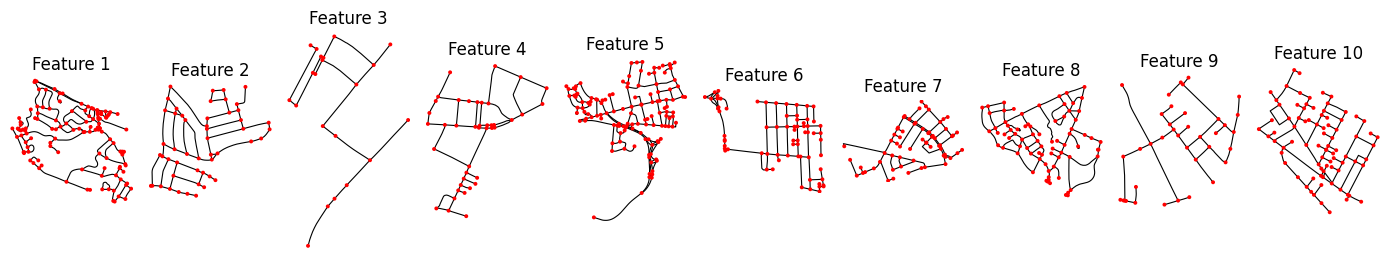

In [6]:
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

geojson_path = NOTEBOOK_DIR / "data" / "urban_patterns_clustered.geojson"
gdf = gpd.read_file(geojson_path)

if gdf.crs is not None and gdf.crs.to_epsg() != 4326:
    gdf = gdf.to_crs(4326)

first_two = gdf.head(10)

def to_single_polygon(geom):
    if geom.geom_type == "Polygon":
        return geom
    if geom.geom_type == "MultiPolygon":
        return max(geom.geoms, key=lambda p: p.area)
    raise ValueError(f"Unsupported geometry type: {geom.geom_type}")

fig, axes = plt.subplots(1, 10, figsize=(14, 7))

for i, (_, row) in enumerate(first_two.iterrows()):
    polygon = to_single_polygon(row.geometry)
    G = ox.graph_from_polygon(polygon, network_type="drive", simplify=True)

    G = G.to_undirected()
    print(type(G))

    ox.plot_graph(
        G,
        ax=axes[i],
        node_size=8,          # vertices visible
        node_color="red",
        edge_linewidth=0.8,   # edges visible
        edge_color="black",
        bgcolor="white",
        show=False,
        close=False,
    )
    axes[i].set_title(f"Feature {i+1}")
    axes[i].set_axis_off()

plt.tight_layout()
plt.show()



In [7]:
def normalize_edge_weights(G, weight_attr="weight"):
    # Get maximum weight
    max_weight = max(
        data.get(weight_attr, 1)
        for _, _, data in G.edges(data=True)
    )
    
    # Avoid division by zero
    if max_weight == 0:
        return G

    # Normalize weights
    for u, v, data in G.edges(data=True):
        data[weight_attr] = data.get(weight_attr, 1) / max_weight

    return G

for i in range (0,len(graphs)):
    graphs[i] = normalize_edge_weights(graphs[i])


In [8]:
print(graphs[0].edges(keys=True, data=True))


[(75219025, 75247337, 0, {'osmid': 9638319, 'highway': 'residential', 'lanes': '1', 'name': 'Lamoine Street', 'width': '6.1', 'oneway': False, 'reversed': True, 'length': 37.847584360115135, 'weight': 0.07104884703077197}), (75219025, 75225376, 0, {'osmid': 9638653, 'highway': 'residential', 'lanes': '2', 'name': 'Knox Street', 'width': '12.2', 'oneway': False, 'reversed': True, 'length': 11.582401889981979, 'weight': 0.02174290153633864}), (75219025, 75239770, 0, {'osmid': 9638653, 'highway': 'residential', 'lanes': '2', 'name': 'Knox Street', 'width': '12.2', 'oneway': False, 'reversed': False, 'length': 95.48560469324786, 'geometry': <LINESTRING (-71.181 42.41, -71.18 42.409, -71.18 42.409, -71.18 42.409, -71...>, 'weight': 0.1792490124849461}), (75219025, 75232798, 0, {'osmid': 9638759, 'highway': 'residential', 'lanes': '2', 'name': 'Bellington Street', 'width': '12.2', 'oneway': False, 'reversed': True, 'length': 99.49417469490409, 'geometry': <LINESTRING (-71.18 42.41, -71.18 42

In [23]:
import numpy as np
kts = np.zeros((10,10), dtype=float)

for i in range(len(graphs)):
    for j in range(len(graphs)):
        Q1 = compute_Q(graphs[i])
        Q2 = compute_Q(graphs[j])
        kts[i, j] = kttw(Q1, Q2, gamma=0.05)

In [24]:
import numpy as np

np.set_printoptions(precision=4, suppress=True)
print(kts)


[[1.     0.054  0.083  0.0375 0.2553 0.059  0.075  0.1124 0.0846 0.062 ]
 [0.054  1.     0.3002 0.5807 0.1087 0.4351 0.7149 0.2099 0.3051 0.6031]
 [0.083  0.3002 1.     0.1995 0.1513 0.2049 0.4822 0.2015 0.9953 0.4127]
 [0.0375 0.5807 0.1995 1.     0.0748 0.2741 0.6195 0.1587 0.2032 0.4932]
 [0.2553 0.1087 0.1513 0.0748 1.     0.1108 0.1469 0.1764 0.1543 0.114 ]
 [0.059  0.4351 0.2049 0.2741 0.1108 1.     0.3832 0.3094 0.2085 0.3202]
 [0.075  0.7149 0.4822 0.6195 0.1469 0.3832 1.     0.256  0.4905 0.6773]
 [0.1124 0.2099 0.2015 0.1587 0.1764 0.3094 0.256  1.     0.2054 0.1967]
 [0.0846 0.3051 0.9953 0.2032 0.1543 0.2085 0.4905 0.2054 1.     0.4181]
 [0.062  0.6031 0.4127 0.4932 0.114  0.3202 0.6773 0.1967 0.4181 1.    ]]
